# Finding the narrowest population a drug actually works for

**Scenario.** `ONCB-317` is a fictional targeted therapy for advanced non-small-cell
lung cancer (NSCLC), tested against standard-of-care chemotherapy in a 1,200-patient
randomized controlled trial. The primary efficacy readout is percent change in tumor
burden at 12 weeks (RECIST-style; negative = shrinkage).

**The question this notebook answers:** does `ONCB-317` work for everyone, or is
there a smaller, identifiable population where it works dramatically better -- the
kind of population a real precision-oncology drug (trastuzumab in HER2+ breast
cancer, osimertinib in EGFR-mutant NSCLC) gets approved for?

**Why simulated data.** With a real trial you only ever observe one outcome per
patient -- treated *or* control, never both -- so you can never know a patient's true
individual treatment effect, only estimate it. This is commonly referred to as the fundamental problem of causal inference. That makes it impossible to check
whether a stratification method found the *right* subgroup or just something that
looks good by chance. Here, because the data-generating process is ours
(`src/simulate_trial.py`), we know the ground truth and can grade the method against
it before ever pointing it at real patient data. A T-learner is one of the simplest ways to estimate how much a treatment helps each individual patient. The “T” stands for “two,” because it trains two separate models. A T-learner will split the trial data by arm, fit one model per group, predict both outcomes for every patient, and then subtract to find the conditional average treatment effect (CATE). The pipeline itself (T-learner CATE
estimation -> policy tree subgroup discovery -> validation) doesn't use that ground
truth anywhere -- it's held out purely for grading, exactly like a real analyst would
be held to a pre-registered validation cohort.

**Two kinds of baseline variable are simulated on purpose:**
- *Prognostic* variables affect the outcome in both arms (age, ECOG performance
  status, baseline tumor burden, comorbidities, tumor mutational burden) -- sicker
  patients do worse whether or not they get the drug.
- *Predictive* (moderator) variables change the **size of the treatment effect**
  itself. Here, only two matter: EGFR mutation status and PD-L1 expression. Patients
  who are EGFR-mutant *and* have high PD-L1 expression get a large extra benefit;
  everyone else gets a small background effect. Confusing prognostic variables for
  predictive ones is the single most common mistake in subgroup analysis, and it's
  worth keeping that distinction in mind throughout.


In [1]:
import json
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd

from simulate_trial import FEATURE_COLUMNS, RESPONDER_CATE_THRESHOLD
from modeling import estimate_cate_t_learner
from subgroup_discovery import discover_subgroup
from evaluate import observed_ate, subgroup_vs_ground_truth, cate_calibration
from plotting import (
    plot_forest, plot_calibration, plot_leaf_summary, plot_policy_tree, plot_cate_distribution,
)

pd.set_option("display.max_colwidth", 120)


## 1. The trial data

`data/trial_data.csv` contains baseline
covariates, treatment arm, and outcome. No ground truth is in this file.


In [2]:
df = pd.read_csv("../data/trial_data.csv")
print(f"{len(df)} patients, {df['treatment'].sum()} treated / {(1 - df['treatment']).sum()} control")
df.head()


1200 patients, 591 treated / 609 control


,patient_id,age,sex_male,ecog_ps,smoking_current,smoking_former,histology_squamous,baseline_tumor_burden_mm,comorbidity_index,prior_lines_of_therapy,tumor_mutational_burden,egfr_mutation,pdl1_expression_pct,treatment,tumor_change_pct,objective_response
0,P0000,67.070094,0,0,1,0,0,44.556745,1,0,14.675598,0,2.273551,0,-42.195946,1
1,P0001,72.397134,0,0,0,1,1,79.772360,4,2,8.268889,0,55.771136,0,8.989345,0
2,P0002,67.929495,0,0,0,0,1,52.417395,1,1,3.100230,0,24.458662,1,-1.358175,0
3,P0003,75.102359,0,2,0,1,0,85.041582,2,0,5.386482,0,11.793605,1,7.249651,0
4,P0004,70.126816,0,2,0,0,0,84.590486,0,0,6.695727,0,34.447447,0,19.667676,0


In [3]:
df[FEATURE_COLUMNS + ["treatment", "tumor_change_pct", "objective_response"]].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
age,1200.0,64.31,9.85,35.00,57.69,64.19,71.14,89.00
sex_male,1200.0,0.51,0.50,0.00,0.00,1.00,1.00,1.00
ecog_ps,1200.0,0.68,0.69,0.00,0.00,1.00,1.00,2.00
smoking_current,1200.0,0.31,0.46,0.00,0.00,0.00,1.00,1.00
smoking_former,1200.0,0.54,0.50,0.00,0.00,1.00,1.00,1.00
histology_squamous,1200.0,0.29,0.45,0.00,0.00,0.00,1.00,1.00
baseline_tumor_burden_mm,1200.0,71.15,28.39,15.03,49.70,67.45,88.76,181.29
comorbidity_index,1200.0,1.43,1.22,0.00,0.00,1.00,2.00,7.00
prior_lines_of_therapy,1200.0,0.47,0.66,0.00,0.00,0.00,1.00,2.00
tumor_mutational_burden,1200.0,8.94,5.10,0.66,5.33,7.92,11.40,33.61


## 2. Overall trial result

We first look at the intention-to-treat effect: mean
outcome in the treated arm minus mean outcome in the control arm, with a bootstrap
95% CI.


In [4]:
overall = observed_ate(df)
overall


{'n': 1200,
 'n_treated': 591,
 'n_control': 609,
 'ate': -7.9613699802576505,
 'ci_lo': -9.547801960952635,
 'ci_hi': -6.530253120888878}

That's a real, statistically significant effect (the CI excludes 0) but it's
modest -- a few extra points of tumor shrinkage on average. On this evidence alone, a
team might file it as "works, but not a game-changer" and move on. The rest of this
notebook asks whether that average is hiding something.


## 3. Digging deeper

The classic (and still common) next approach is to slice the trial by one baseline
variable at a time -- age above/below median, mutation-positive vs. negative, etc.
-- and see if the effect looks different in each slice. This is a key area where analysis can go wrong: a *prognostic* variable can look like it's
moderating the treatment effect purely by chance or by confounding with the real
moderator, and a univariate scan can't see a subgroup that only emerges from the
**combination** of two variables.


In [5]:
def univariate_scan(df, columns, min_group=30):
    """Split each variable at its median into high/low halves and compute
    the observed ATE in each half. Falls back to splitting at the modal
    value for skewed low-cardinality variables (e.g. a 0/1 flag, or a count
    where most patients are 0) where a median split would put everyone on
    one side."""
    rows = []
    for col in columns:
        values = df[col]
        high_mask = values >= values.median()
        low_mask = ~high_mask
        if high_mask.sum() < min_group or low_mask.sum() < min_group:
            mode_val = values.mode().iloc[0]
            high_mask = values > mode_val
            low_mask = values <= mode_val
        if high_mask.sum() < min_group or low_mask.sum() < min_group:
            continue
        for label, mask in [("high", high_mask), ("low", low_mask)]:
            res = observed_ate(df, mask.to_numpy())
            rows.append({"variable": col, "half": label, **res})
    return pd.DataFrame(rows)

scan = univariate_scan(df, FEATURE_COLUMNS)
scan.sort_values("ate")[["variable", "half", "n", "ate", "ci_lo", "ci_hi"]].head(10)


,variable,half,n,ate,ci_lo,ci_hi
20,egfr_mutation,high,267,-16.312129,-19.966547,-12.840514
22,pdl1_expression_pct,high,600,-10.746337,-12.982577,-8.541620
19,tumor_mutational_burden,low,600,-9.125686,-10.943546,-7.360746
8,smoking_former,high,649,-8.630290,-10.854195,-6.590551
0,age,high,600,-8.501049,-10.789701,-6.351699
12,baseline_tumor_burden_mm,high,600,-8.456276,-10.601091,-6.447548
7,smoking_current,low,827,-8.409688,-10.195272,-6.694082
11,histology_squamous,low,852,-8.299507,-10.188724,-6.483221
17,prior_lines_of_therapy,low,756,-8.196015,-10.243737,-6.376030
15,comorbidity_index,low,313,-8.102983,-11.102868,-5.145209


Skimming this table, `egfr_mutation = high` (i.e. mutation-positive) clearly stands out on its own, which is an example of what a typical univariate scan *can* catch. But no single split gets close to the
~-32 effect the true responder subgroup actually has, because no single variable captures the **combination** of EGFR status and another variable(s) that may be contributing to what we're seeing in the true responder results. That's the gap a per-patient model of treatment effect is meant to
close.


## 4. Estimate individual treatment effects: cross-fitted T-learner

The approach: fit two random forests -- one on the treated arm, one on the control
arm -- each predicting the outcome from baseline covariates. A patient's estimated
treatment effect (CATE, conditional average treatment effect) is the difference
between what the two models would have predicted for them:

`CATE_hat(x) = E[Y | X=x, treated] - E[Y | X=x, control]`

This is the simplest "meta-learner" for heterogeneous treatment effects (Kunzel et
al., 2019). To avoid the model partly memorizing each patient it's scoring (which
would inflate apparent heterogeneity), estimates are *cross-fitted*: each patient is
scored by a model trained only on the other folds -- the same "honesty" principle
behind causal forests.


Estimated CATE: mean=-7.8, std=5.1, min=-31.8, max=4.1


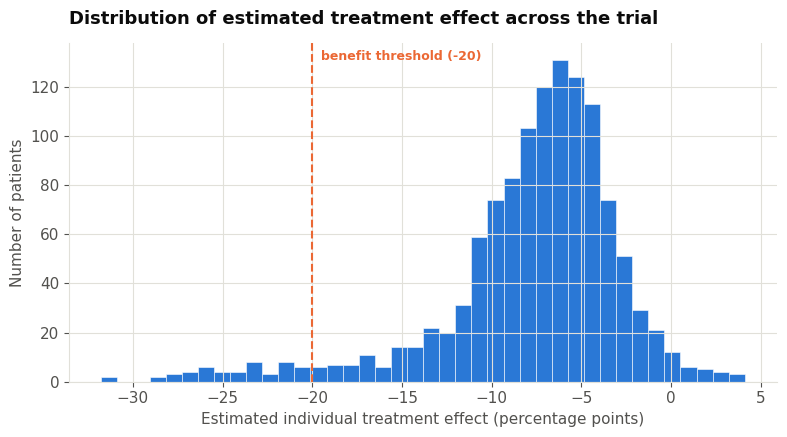

In [6]:
cate_result = estimate_cate_t_learner(df, FEATURE_COLUMNS, n_splits=5, seed=0)
cate_hat = cate_result["cate_hat"]

print(f"Estimated CATE: mean={cate_hat.mean():.1f}, std={cate_hat.std():.1f}, "
      f"min={cate_hat.min():.1f}, max={cate_hat.max():.1f}")
plot_cate_distribution(cate_hat, benefit_threshold=RESPONDER_CATE_THRESHOLD);


Most patients cluster around a modest effect (matching the population-level
ATE from section 2), with a smaller tail of patients estimated to benefit
substantially more -- exactly the shape you'd expect if a real minority-responder
subgroup exists underneath an unremarkable average.


## 5. Sanity check: comparing the model's estimates to ground truth

This step is what confirms the method the right to be trusted on data where the answer key
doesn't exist.

Note: Only possible here because this is simulated data with a known answer key.


Pearson r (estimated vs. true CATE): 0.66
Mean absolute error: 3.3 percentage points


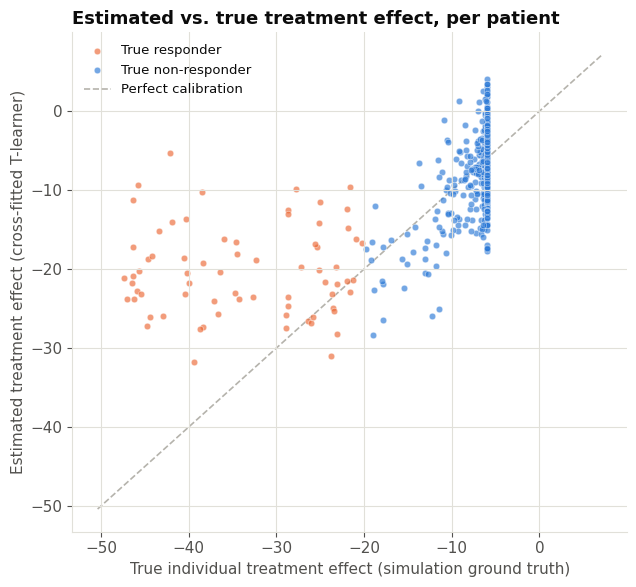

In [7]:
truth = json.load(open("../data/ground_truth.json"))
true_cate = np.array(truth["true_cate"])
true_responder = np.array(truth["true_responder"])

calib = cate_calibration(cate_hat, true_cate)
print(f"Pearson r (estimated vs. true CATE): {calib['pearson_r']:.2f}")
print(f"Mean absolute error: {calib['mae']:.1f} percentage points")
plot_calibration(cate_hat, true_cate, true_responder);


The correlation is far from perfect, which is to be expected given the complexity of individual-level treatment effect
estimation, and our relatively small population of 1,200 patients enrolled in our trial. 

But, the model clearly separates true responders from true
non-responders on average, and it never estimates
a *false* large effect for a true non-responder. That's enough to be useful for
subgroup discovery, which only needs the *ranking* to be reasonable, not each
individual point estimate to be exact.


## 6. Converting per-patient estimates into eligibility criteria that a trial protocol could actually use

This step fits a shallow decision tree
(depth <= 3) to predict the estimated CATE from
baseline covariates, then reads off the leaves as candidate subgroup rules -- the
"policy tree" idea from Athey & Wager, and the same spirit as the older "Virtual
Twins" method (Foster, Taylor & Ruberg, 2011). The tree is a compression step for
interpretability; the T-learner above is still doing the actual causal estimation.


In [8]:
discovery = discover_subgroup(
    df[FEATURE_COLUMNS], cate_hat, benefit_threshold=RESPONDER_CATE_THRESHOLD, max_depth=3,
)
discovery["leaf_summary"]


,leaf_id,rule,n_patients,pct_of_population,mean_cate_hat
0,13,egfr_mutation > 0.50 AND pdl1_expression_pct > 34.76 AND tumor_mutational_burden <= 8.67,65,0.054167,-22.699971
1,14,egfr_mutation > 0.50 AND pdl1_expression_pct > 34.76 AND tumor_mutational_burden > 8.67,38,0.031667,-14.061422
2,10,egfr_mutation > 0.50 AND pdl1_expression_pct <= 34.76 AND tumor_mutational_burden <= 7.19,53,0.044167,-12.113202
3,4,egfr_mutation <= 0.50 AND ecog_ps <= 0.50 AND pdl1_expression_pct > 35.64,166,0.138333,-8.511123
4,6,egfr_mutation <= 0.50 AND ecog_ps > 0.50 AND tumor_mutational_burden <= 7.21,222,0.185000,-6.740575
5,11,egfr_mutation > 0.50 AND pdl1_expression_pct <= 34.76 AND tumor_mutational_burden > 7.19,111,0.092500,-6.576476
6,3,egfr_mutation <= 0.50 AND ecog_ps <= 0.50 AND pdl1_expression_pct <= 35.64,255,0.212500,-6.455401
7,7,egfr_mutation <= 0.50 AND ecog_ps > 0.50 AND tumor_mutational_burden > 7.21,290,0.241667,-4.789622


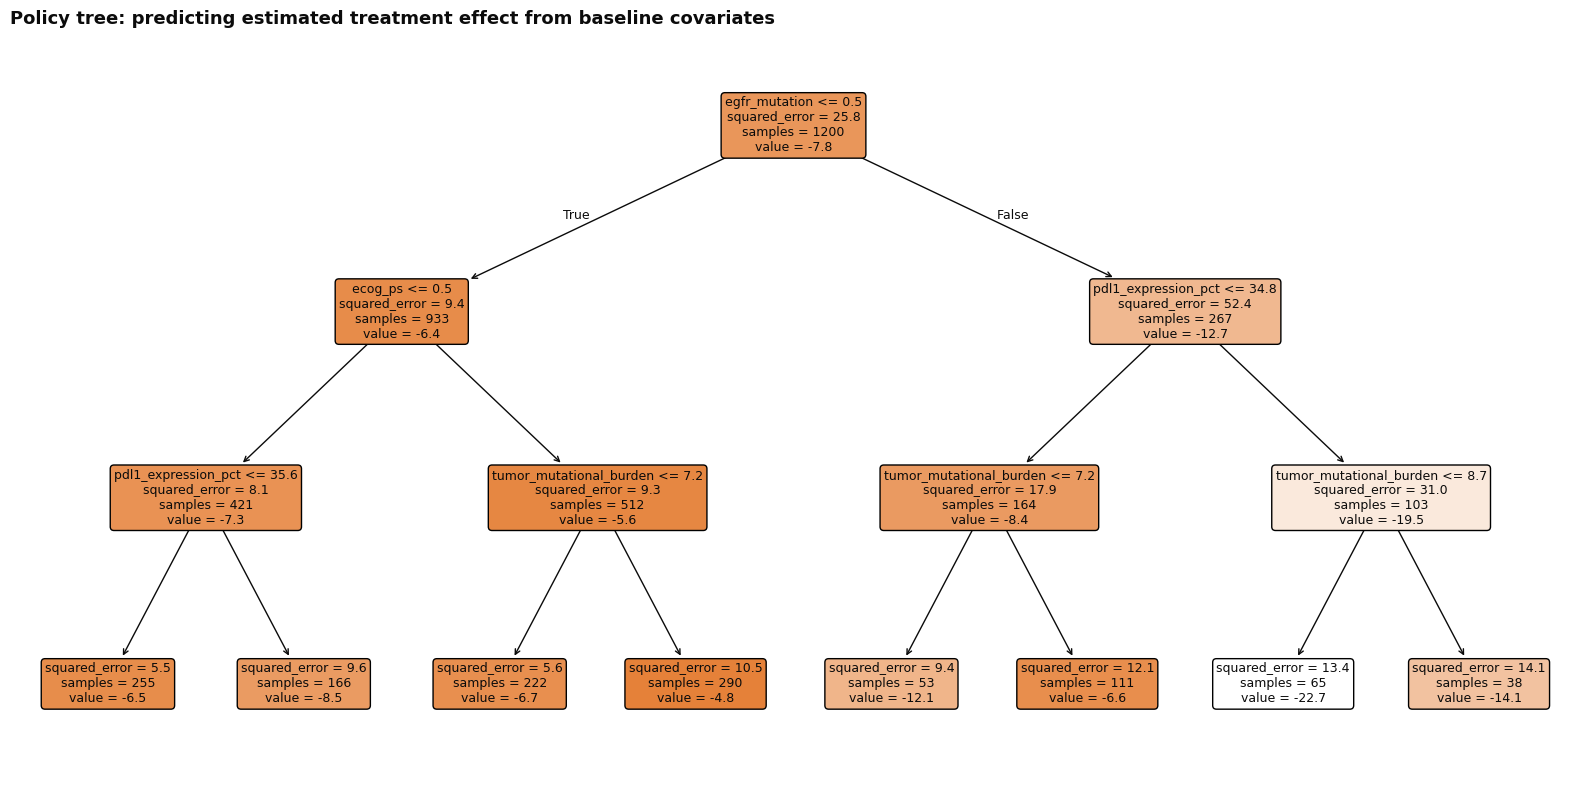

In [9]:
plot_policy_tree(discovery["tree"], FEATURE_COLUMNS);


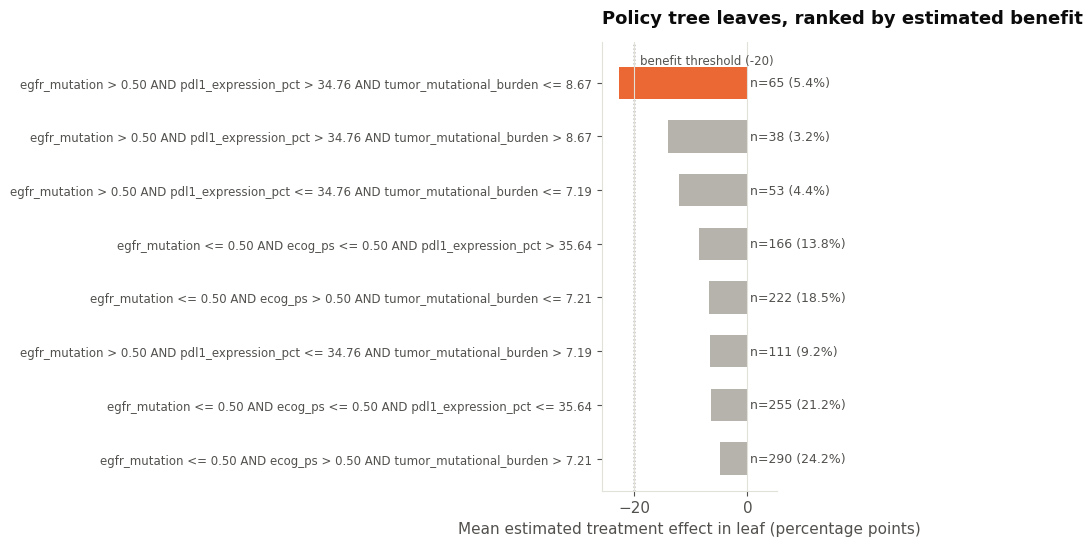

In [10]:
plot_leaf_summary(discovery["leaf_summary"], benefit_threshold=RESPONDER_CATE_THRESHOLD);


In [11]:
print("Discovered eligibility rule(s):")
for rule in discovery["rules"]:
    print(f"  - {rule}")
print(f"\n{discovery['in_subgroup'].sum()} of {len(df)} patients "
      f"({discovery['in_subgroup'].mean():.1%}) fall into the discovered subgroup.")


Discovered eligibility rule(s):
  - egfr_mutation > 0.50 AND pdl1_expression_pct > 34.76 AND tumor_mutational_burden <= 8.67

65 of 1200 patients (5.4%) fall into the discovered subgroup.


The tree recovers the two variables that seem to actually drive the true effect --
EGFR mutation status (which we already knew from the univariate scan) **and** PD-L1 expression -- and lands on a PD-L1 cutoff close to the
~50% threshold used to generate the data. 

It also picked up a third condition on
tumor mutational burden that isn't part of the true rule. This is the expected behavior of a flexible model fit to one trial's worth of noisy
data, and it's exactly why a discovered rule like this belongs in a **pre-registered,
independent validation cohort** before it ever becomes an actual trial inclusion
criterion -- not straight from a single discovery-set decision tree.


## 7. Grade the discovered subgroup against the truth

Again, only possible because the ground truth is known here.


In [12]:
grading = subgroup_vs_ground_truth(discovery["in_subgroup"], true_responder)
grading


{'precision': 0.7076923076923077,
 'recall': 0.647887323943662,
 'f1': 0.6764705882352942,
 'n_discovered': 65,
 'n_true_responders': 71,
 'n_overlap': 46}

Precision and recall in the 60-70% range against a subgroup that makes up
under 6% of the trial is a solid result for a single 1,200-patient discovery run --
not perfect, which would itself be a red flag for overfitting, but a clear,
actionable signal recovered from data that on its own only showed a modest average
effect.

Responders are rare, which makes the problem hard. With a random 65 patients, we see that only about 6% of them (roughly 4 people) will be true responders. The tree’s 71% precision is about 12 times better than chance, but of course, still not perfect. Finding a needle that small in noisy data, where you only ever see one outcome per patient, is the hard part. That’s why this is can be considered a solid result, but far from a black-and-white prediction model. 

## 8. Finally, observed treatment effect by group

Everything above used estimated or true CATE. But, we also need to look at **observed outcomes**, split by whether a
patient falls in the discovered subgroup -- the same difference-in-means-with-CI
computation as section 2, just applied to a smarter split.


In [13]:
groups = {
    "Overall trial population": overall,
    "Discovered subgroup": observed_ate(df, discovery["in_subgroup"]),
    "Everyone else": observed_ate(df, ~discovery["in_subgroup"]),
}
pd.DataFrame(groups).T[["n", "ate", "ci_lo", "ci_hi"]]


,n,ate,ci_lo,ci_hi
Overall trial population,1200.0,-7.961370,-9.547802,-6.530253
Discovered subgroup,65.0,-31.910865,-38.492078,-25.963245
Everyone else,1135.0,-6.659821,-8.247445,-5.031669


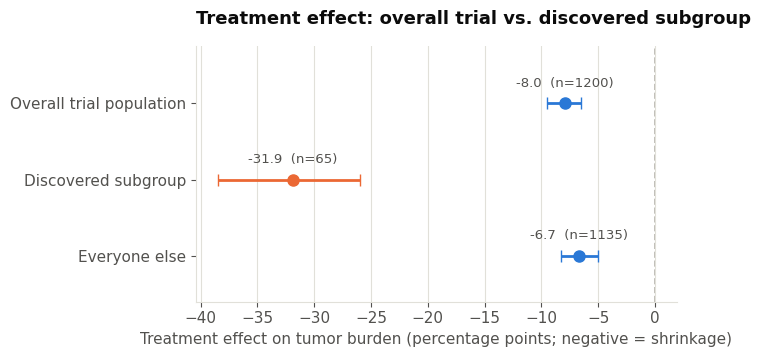

In [14]:
plot_forest(
    groups, highlight="Discovered subgroup",
    title="Treatment effect: overall trial vs. discovered subgroup",
);


This is the headline finding: a population-level effect of roughly -8 points
resolves into a ~-32 point effect inside the discovered subgroup (EGFR-mutant,
PD-L1-high patients) and a much smaller, largely background effect (~-7 points)
everywhere else. The drug doesn't work moderately for everyone -- it works
dramatically for a specific, identifiable ~5-6% of patients, and only modestly for
the rest. That's the actionable version of "does this drug work": not a single
average, but a population definition a follow-up trial could actually enroll
against.


## Summary and caveats

- The **average treatment effect across the whole trial understates** what the drug
  does for the patients it actually works well for, and overstates what it does for
  everyone else -- the classic argument for looking past the topline number in any
  RCT with a plausible biological reason to expect heterogeneity.
- A **cross-fitted T-learner** turned noisy per-patient outcomes into per-patient
  effect estimates without letting the model memorize the patients it was scoring.
- A shallow **policy tree** compressed those estimates into a short, human-readable
  eligibility rule -- the actual deliverable a protocol amendment would use.
- Validated here against **known ground truth**, the discovered subgroup had solid
  (not perfect) precision/recall, and it picked up one extra condition beyond the
  true rule -- a reminder that discovered subgroups are hypotheses generated from one
  dataset, not conclusions, until confirmed in an independent cohort.
- **What this notebook is not:** a substitute for a pre-specified, biologically
  motivated hypothesis; a substitute for external/prospective validation; or a claim
  that this exact method (a T-learner + shallow tree) is the best available one. Causal
  forests, X-/R-learners, and doubly-robust estimators are natural next steps, and
  would be worth comparing against this baseline before finalizing a real protocol.
